# 10 · Adapt speech recognition

Can an adapter improve recognition under a known acoustic shift and keep clean
speech accuracy? Compare the same Whisper checkpoint on clean, channel-corrupted
and deterministically conditioned audio. Train a small adapter on the
unconditioned corruptions, then test it on the same untouched speakers.

Audiobook passages stand in for spoken invoice instructions. This lab tests
an acoustic change in English. It makes no claim about call-centre audio,
measurements on real invoices, or transfer to other languages.

## 1. Choose the runtime

Select a T4 in Colab. The default profile bounds downloads and training. Set
COURSE_PROFILE to full before starting the kernel to use the larger profile.
Profile names denote workload sizes. Run time and peak memory are measured
from the actual execution.

In [1]:
import os
import subprocess
import sys
import torch

if not torch.cuda.is_available() or "T4" not in torch.cuda.get_device_name():
    raise RuntimeError("Select a Colab T4 for this notebook.")

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "transformers==4.57.1",
     "datasets==3.6.0", "peft==0.17.1", "jiwer==4.0.0", "soundfile==0.13.1"],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.57.1', 'datasets==3.6.0', 'peft==0.17.1', 'jiwer==4.0.0', 'soundfile==0.13.1'], returncode=0)

In [2]:
from collections import Counter, defaultdict
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from time import perf_counter
import importlib.metadata
import json
import random
import re

import jiwer
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import soundfile as sf
from datasets import Audio, load_dataset
from peft import LoraConfig, get_peft_model
from scipy.signal import butter, resample_poly, sosfiltfilt
from transformers import WhisperForConditionalGeneration, WhisperProcessor

MODEL_ID = "openai/whisper-base"
MODEL_REVISION = "e37978b90ca9030d5170a5c07aadb050351a65bb"
DATA_ID = "openslr/librispeech_asr"
DATA_REVISION = "71cacbfb7e2354c4226d01e70d77d5fca3d04ba1"
PROFILE = os.environ.get("COURSE_PROFILE", "profile")
PROFILES = {
    "profile": {"train_cap": 32, "test_cap": 24, "steps": 16},
    "full": {"train_cap": 128, "test_cap": 72, "steps": 64},
}
LIMITS = PROFILES[PROFILE]
SEED = 391
SAMPLE_RATE = 16_000
SNR_DB = 8.0
MAX_SECONDS = 12
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
random.seed(SEED)
torch.manual_seed(SEED)
set_matplotlib_formats("svg")
plt.rcParams["svg.fonttype"] = "none"
device = torch.device("cuda")

## 2. Put one channel on two clean splits

Use the published train.100 and test splits of LibriSpeech clean. Stream a
bounded prefix with a per-speaker cap and log the selected IDs. This is a
deterministic teaching subset rather than a population sample. Test speakers
never contribute training clips. Each test clip is used in all five arms.

Downsample to 8 kHz, upsample to 16 kHz and then add deterministic noise at
a fixed signal-to-noise ratio. The fixed input-conditioning arm applies a
speech-band filter without training. It cannot restore discarded frequencies.

In [3]:
# SMOKE LIBRARY START
NUMBER = re.compile(
    r"\b(?:\d+(?:\.\d+)?|zero|one|two|three|four|five|six|seven|eight|nine|ten|"
    r"eleven|twelve|thirteen|fourteen|fifteen|sixteen|seventeen|eighteen|"
    r"nineteen|twenty|thirty|forty|fifty|sixty|seventy|eighty|ninety|"
    r"hundred|thousand|million)\b"
)
SINGLE_NUMBERS = dict(zip(
    "zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen seventeen eighteen nineteen twenty".split(),
    map(str, range(21)),
))
SINGLE_NUMBERS.update(dict(zip(
    "thirty forty fifty sixty seventy eighty ninety".split(), map(str, range(30, 100, 10)),
)))


def channel_corruption(wave, key, snr_db):
    reduced = resample_poly(wave, 1, 2)
    restored = resample_poly(reduced, 2, 1)[:len(wave)]
    seed = int.from_bytes(sha256(key.encode()).digest()[:8], "big")
    noise = np.random.default_rng(seed).standard_normal(len(wave))
    noise_power = np.mean(noise ** 2)
    signal_power = np.mean(restored ** 2)
    weight = np.sqrt(signal_power / (10 ** (snr_db / 10) * noise_power))
    mixed = restored + weight * noise
    # Scale all samples together only when needed, retaining the SNR.
    return (mixed / max(1.0, float(np.max(np.abs(mixed))))).astype(np.float32)


def conditioned(wave, rate):
    sos = butter(4, (300, 3400), btype="bandpass", fs=rate, output="sos")
    return sosfiltfilt(sos, wave).astype(np.float32)


def normalize(text):
    return " ".join(re.findall(r"[a-z0-9]+", text.lower()))


def numeric_tokens(text):
    return [SINGLE_NUMBERS.get(token, token) for token in NUMBER.findall(text.lower())]
# SMOKE LIBRARY END


def load_clips(split, cap, per_speaker):
    stream = load_dataset(DATA_ID, "clean", split=split, revision=DATA_REVISION, streaming=True)
    stream = stream.cast_column("audio", Audio(decode=False))
    counts = Counter()
    clips = []
    for raw in stream:
        speaker = int(raw["speaker_id"])
        if counts[speaker] >= per_speaker:
            continue
        audio = raw["audio"]
        if not audio["bytes"]:
            raise RuntimeError("The pinned stream did not include audio bytes.")
        wave, rate = sf.read(BytesIO(audio["bytes"]), dtype="float32")
        if rate != SAMPLE_RATE or wave.ndim != 1 or not np.isfinite(wave).all():
            raise ValueError(f"Unexpected audio for {raw['id']}")
        if not 1 <= len(wave) / rate <= MAX_SECONDS or not normalize(raw["text"]):
            continue
        item = {
            "id": raw["id"], "speaker": speaker, "reference": raw["text"], "wave": wave,
            "shifted": channel_corruption(wave, raw["id"], SNR_DB),
        }
        clips.append(item)
        counts[speaker] += 1
        if len(clips) == cap:
            break
    if len(clips) != cap:
        raise RuntimeError(f"{split} provided only {len(clips)} matching clips")
    return clips


train_clips = load_clips("train.100", LIMITS["train_cap"], per_speaker=8)
test_clips = load_clips("test", LIMITS["test_cap"], per_speaker=6)
assert {row["speaker"] for row in train_clips}.isdisjoint(row["speaker"] for row in test_clips)
print("Selected training and test clips:", len(train_clips), len(test_clips))
print("Distinct test speakers:", len({row["speaker"] for row in test_clips}))

Selected training and test clips: 32 24
Distinct test speakers: 4


## 3. Measure the frozen controls

Use greedy English transcription for all arms. Compare the original clean
waveform, the degraded channel and the same degraded waveform after applying
the fixed filter. The waveform is the only thing that changes in these arms.
Report inference time as a ratio of audio duration, excluding waveform prep and
feature extraction.

In [4]:
processor = WhisperProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
model = WhisperForConditionalGeneration.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, attn_implementation="eager",
).to(device)
model.eval()


def to_features(wave):
    return processor.feature_extractor(
        wave, sampling_rate=SAMPLE_RATE, return_tensors="pt", return_attention_mask=True,
    ).to(device)


@torch.inference_mode()
def transcribe(model_to_read, wave):
    features = to_features(wave)
    torch.cuda.synchronize()
    start = perf_counter()
    token_ids = model_to_read.generate(
        **features, language="en", task="transcribe", do_sample=False, num_beams=1,
        max_new_tokens=144, return_timestamps=False,
    )
    torch.cuda.synchronize()
    elapsed = perf_counter() - start
    return processor.batch_decode(token_ids, skip_special_tokens=True)[0], elapsed


def test_arm(model_to_read, arm, waveform):
    model_to_read.eval()
    transcribe(model_to_read, waveform(test_clips[0]))  # warm up all arms alike
    rows = []
    for clip in test_clips:
        wave = waveform(clip)
        prediction, seconds = transcribe(model_to_read, wave)
        words = jiwer.process_words(normalize(clip["reference"]), normalize(prediction))
        chars = jiwer.process_characters(normalize(clip["reference"]), normalize(prediction))
        numbers = numeric_tokens(clip["reference"])
        rows.append({
            "arm": arm, "id": clip["id"], "speaker": clip["speaker"],
            "reference": clip["reference"], "prediction": prediction,
            "word_edits": words.substitutions + words.deletions + words.insertions,
            "word_total": len(normalize(clip["reference"]).split()),
            "char_edits": chars.substitutions + chars.deletions + chars.insertions,
            "char_total": len(normalize(clip["reference"])),
            "numeric_exact": numeric_tokens(prediction) == numbers if numbers else None,
            "decode_seconds": seconds, "audio_seconds": len(wave) / SAMPLE_RATE,
        })
    return rows


rows = []
rows += test_arm(model, "frozen-clean", lambda c: c["wave"])
rows += test_arm(model, "frozen-corrupted", lambda c: c["shifted"])
rows += test_arm(model, "frozen-conditioned", lambda c: conditioned(c["shifted"], SAMPLE_RATE))

## 4. Fit an encoder-decoder adapter

Add low-rank updates to query and value projections of the existing attention
layers. Keep the base weights and waveform feature extractor fixed. Train on
corrupted waveforms and the original supervised transcripts. Trainability is
checked before the first step. The optimizer sees only adapter parameters.

In [5]:
adapter = get_peft_model(
    model, LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"], lora_dropout=0.05),
)
trainable = [(name, param) for name, param in adapter.named_parameters() if param.requires_grad]
assert trainable and all("lora_" in name for name, _ in trainable)
processor.tokenizer.set_prefix_tokens(language="en", task="transcribe", predict_timestamps=False)
adapter.train()
adapter.config.use_cache = False
trainable_parameters = [parameter for _, parameter in trainable]


def train_step(clip, optimiser, scaler):
    features = to_features(clip["shifted"])
    labels = processor.tokenizer(clip["reference"].lower(), return_tensors="pt").input_ids.to(device)
    if labels[0, 0].item() == model.config.decoder_start_token_id:
        labels = labels[:, 1:]
    optimiser.zero_grad(set_to_none=True)
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        loss = adapter(**features, labels=labels, use_cache=False).loss
    if not torch.isfinite(loss):
        raise FloatingPointError(f"Nonfinite ASR loss for {clip['id']}")
    scaler.scale(loss).backward()
    scaler.unscale_(optimiser)
    torch.nn.utils.clip_grad_norm_(trainable_parameters, 1.0)
    previous_scale = scaler.get_scale()
    scaler.step(optimiser)
    scaler.update()
    return loss.item(), scaler.get_scale() >= previous_scale


# Run one real update before the scored fit and restore adapter tensors and RNG.
initial_trainable = [parameter.detach().cpu().clone() for parameter in trainable_parameters]
longest = max(train_clips, key=lambda clip: len(clip["reference"]))
probe_optim = torch.optim.AdamW(trainable_parameters, lr=1e-4)
torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()
profile_started = perf_counter()
with torch.random.fork_rng(devices=[torch.cuda.current_device()]):
    probe_loss, probe_updated = train_step(longest, probe_optim, torch.amp.GradScaler("cuda", init_scale=1024))
torch.cuda.synchronize()
preflight = {
    "clip": longest["id"], "seconds": perf_counter() - profile_started,
    "peak_reserved_bytes": torch.cuda.max_memory_reserved(),
    "peak_allocated_bytes": torch.cuda.max_memory_allocated(),
    "updated": probe_updated, "loss": probe_loss,
}
(OUT / "t4-profile.json").write_text(json.dumps(preflight, indent=2), encoding="utf-8")
print("T4 preflight:", preflight)
if not probe_updated or preflight["seconds"] > 30 or preflight["peak_reserved_bytes"] > 12 * 1024**3:
    raise RuntimeError("Whisper adapter preflight exceeds its update, time or T4 memory guard.")
with torch.no_grad():
    for parameter, initial in zip(trainable_parameters, initial_trainable, strict=True):
        parameter.copy_(initial)
del probe_optim, initial_trainable
adapter.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

optim = torch.optim.AdamW(trainable_parameters, lr=1e-4)
torch.cuda.reset_peak_memory_stats()
scaler = torch.amp.GradScaler("cuda", init_scale=1024)
started = perf_counter()
history = []
rng = random.Random(SEED)
order = list(range(len(train_clips)))
rng.shuffle(order)
for step in range(LIMITS["steps"]):
    clip = train_clips[order[step % len(order)]]
    loss, updated = train_step(clip, optim, scaler)
    history.append({"step": step + 1, "loss": loss, "id": clip["id"], "optimizer_updated": updated})
torch.cuda.synchronize()
training_seconds = perf_counter() - started
peak_allocated = torch.cuda.max_memory_allocated()
assert any(parameter.detach().count_nonzero().item() for name, parameter in trainable if ".lora_B." in name)
adapter.save_pretrained(OUT / "whisper-lora")
adapter.config.use_cache = True
rows += test_arm(adapter, "adapted-clean", lambda c: c["wave"])
rows += test_arm(adapter, "adapted-corrupted", lambda c: c["shifted"])

T4 preflight: {'clip': '7800-283478-0021', 'seconds': 0.41708689099959884, 'peak_reserved_bytes': 1480589312, 'peak_allocated_bytes': 1313105920, 'updated': True, 'loss': 1.205765962600708}


## 5. Compare paired retention and adaptation

Word and character error rates divide all edits by their respective reference
token totals. Numeric exactness is a separate restricted diagnostic and reports
its own denominator. It folds only single number words such as "six" into an
equivalent digit. It does not infer that a multiword number phrase and a
formatted amount express the same value. Inspect the paired raw transcripts
for the failures that would change a financial instruction.

{
  "gpu": "Tesla T4",
  "cuda": "13.0",
  "profile": "profile",
  "limits": {
    "train_cap": 32,
    "test_cap": 24,
    "steps": 16
  },
  "model": "openai/whisper-base",
  "model_revision": "e37978b90ca9030d5170a5c07aadb050351a65bb",
  "data": "openslr/librispeech_asr",
  "data_revision": "71cacbfb7e2354c4226d01e70d77d5fca3d04ba1",
  "seed": 391,
  "sample_rate": 16000,
  "snr_db": 8.0,
  "training_seconds": 2.795956728999954,
  "peak_allocated_bytes": 1326121984,
  "trainable_parameters": 294912,
  "optimizer_updates": 16,
  "train_ids": [
    "374-180298-0003",
    "374-180298-0019",
    "374-180298-0026",
    "374-180298-0035",
    "374-180298-0038",
    "374-180298-0039",
    "374-180298-0043",
    "374-180298-0045",
    "7800-283478-0005",
    "7800-283478-0018",
    "7800-283478-0019",
    "7800-283478-0020",
    "7800-283478-0021",
    "7800-283478-0025",
    "7800-283492-0006",
    "7800-283492-0007",
    "2514-149482-0012",
    "2514-149482-0031",
    "2514-149482-0036",


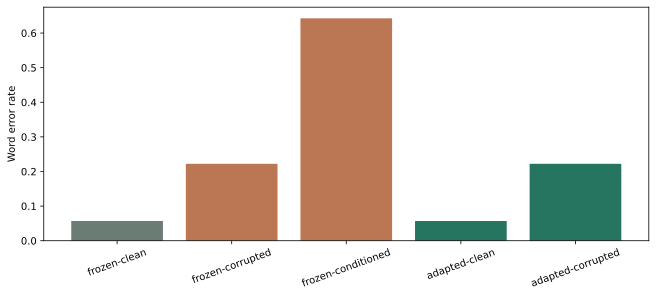

Largest observed word-edit delta, adapted minus frozen, on the corrupted test slice:
{
  "frozen": {
    "arm": "frozen-corrupted",
    "id": "5639-40744-0005",
    "speaker": 5639,
    "reference": "FINALLY THE ONE PARTY WENT OFF EXULTING AND THE OTHER WAS LEFT IN DESOLATION AND WOE",
    "prediction": " Finally, the one party went off exhausting and the other was left in desolation and war.",
    "word_edits": 2,
    "word_total": 16,
    "char_edits": 5,
    "char_total": 84,
    "numeric_exact": true,
    "decode_seconds": 0.31142243100021005,
    "audio_seconds": 5.645
  },
  "adapted": {
    "arm": "adapted-corrupted",
    "id": "5639-40744-0005",
    "speaker": 5639,
    "reference": "FINALLY THE ONE PARTY WENT OFF EXULTING AND THE OTHER WAS LEFT IN DESOLATION AND WOE",
    "prediction": " Finally, the one party went off exalting and the other was left in deflation and war.",
    "word_edits": 3,
    "word_total": 16,
    "char_edits": 5,
    "char_total": 84,
    "numeric_exact

In [6]:
def aggregate(records):
    numeric = [r["numeric_exact"] for r in records if r["numeric_exact"] is not None]
    return {
        "clips": len(records),
        "wer": sum(r["word_edits"] for r in records) / sum(r["word_total"] for r in records),
        "cer": sum(r["char_edits"] for r in records) / sum(r["char_total"] for r in records),
        "numeric_exact": sum(numeric) / len(numeric) if numeric else None,
        "numeric_denominator": len(numeric),
        "decode_real_time_factor": sum(r["decode_seconds"] for r in records) / sum(r["audio_seconds"] for r in records),
    }


by_arm = defaultdict(list)
for row in rows:
    by_arm[row["arm"]].append(row)
assert all({r["id"] for r in arm} == {c["id"] for c in test_clips} for arm in by_arm.values())
scores = {arm: aggregate(records) for arm, records in by_arm.items()}

def paired_wer_delta(treatment, control):
    treated = {r["id"]: r for r in by_arm[treatment]}
    controls = {r["id"]: r for r in by_arm[control]}
    speaker_for = {clip["id"]: clip["speaker"] for clip in test_clips}
    per_speaker = defaultdict(lambda: [0, 0])
    for key, row in treated.items():
        edits_words = per_speaker[speaker_for[key]]
        edits_words[0] += row["word_edits"] - controls[key]["word_edits"]
        edits_words[1] += row["word_total"]
    deltas, counts = np.asarray([per_speaker[k] for k in sorted(per_speaker)]).T
    rng = np.random.default_rng(SEED)
    picks = rng.integers(0, len(deltas), size=(2000, len(deltas)))
    boot = deltas[picks].sum(axis=1) / counts[picks].sum(axis=1)
    return {"delta": float(deltas.sum() / counts.sum()),
            "p025": float(np.percentile(boot, 2.5)), "p975": float(np.percentile(boot, 97.5)),
            "speakers": len(deltas)}


paired = {f"{a}_minus_{b}": paired_wer_delta(a, b) for a, b in (
    ("frozen-conditioned", "frozen-corrupted"),
    ("adapted-corrupted", "frozen-corrupted"),
    ("adapted-clean", "frozen-clean"),
)}

report = {
    "gpu": torch.cuda.get_device_name(), "cuda": torch.version.cuda, "profile": PROFILE, "limits": LIMITS,
    "model": MODEL_ID, "model_revision": MODEL_REVISION, "data": DATA_ID, "data_revision": DATA_REVISION,
    "seed": SEED, "sample_rate": SAMPLE_RATE, "snr_db": SNR_DB, "training_seconds": training_seconds,
    "peak_allocated_bytes": peak_allocated, "trainable_parameters": sum(p.numel() for _, p in trainable),
    "optimizer_updates": sum(r["optimizer_updated"] for r in history),
    "train_ids": [r["id"] for r in train_clips], "test_ids": [r["id"] for r in test_clips],
    "packages": {package: importlib.metadata.version(package) for package in ("torch", "datasets", "transformers", "peft", "jiwer")},
    "scores": scores, "paired_wer_difference": paired, "t4_preflight": preflight,
}
(OUT / "report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
(OUT / "examples.jsonl").write_text("".join(json.dumps(r) + "\n" for r in rows), encoding="utf-8")
(OUT / "train.jsonl").write_text("".join(json.dumps(r) + "\n" for r in history), encoding="utf-8")
print(json.dumps(report, indent=2))

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.bar(list(scores), [v["wer"] for v in scores.values()], color=["#6b7c74", "#bb7754", "#bb7754", "#257560", "#257560"])
ax.set_ylabel("Word error rate")
ax.tick_params(axis="x", rotation=20)
fig.savefig(OUT / "word-errors.svg")
plt.show()

corrupted = {item["id"]: item for item in by_arm["frozen-corrupted"]}
adapted = {item["id"]: item for item in by_arm["adapted-corrupted"]}
worst_for_adapter = max(adapted, key=lambda key: adapted[key]["word_edits"] - corrupted[key]["word_edits"])
print("Largest observed word-edit delta, adapted minus frozen, on the corrupted test slice:")
print(json.dumps({"frozen": corrupted[worst_for_adapter], "adapted": adapted[worst_for_adapter]}, indent=2))
example = next(row for row in test_clips if row["id"] == worst_for_adapter)
def export_audio_example(clip, name):
    waves = {
        "clean": clip["wave"], "corrupted": clip["shifted"],
        "conditioned": conditioned(clip["shifted"], SAMPLE_RATE),
    }
    for condition, wave in waves.items():
        sf.write(OUT / f"{name}-{condition}.wav", wave, SAMPLE_RATE, subtype="FLOAT")
    matches = [row for row in rows if row["id"] == clip["id"]]
    (OUT / f"{name}.json").write_text(json.dumps(matches, indent=2), encoding="utf-8")


export_audio_example(test_clips[0], "opening")
export_audio_example(example, "regression")

## Read the result

Open report.json and examples.jsonl together. Compare corrupted frozen with
corrupted adapted for the intended improvement, and clean frozen with clean
adapted for retention. Conditioning only changes the waveform. Review the
transcript where the adapter lost most ground before promoting the adapter.
The report uses a paired bootstrap over speakers to keep each speaker’s
utterances together. The small profile yields a coarse uncertainty estimate.
This small speaker subset, synthetic channel and single training seed
provide teaching evidence for these arms rather than a production threshold.

[Whisper paper](https://arxiv.org/abs/2212.04356) ·
[Whisper API](https://huggingface.co/docs/transformers/v4.57.1/model_doc/whisper) ·
[LibriSpeech data](https://www.openslr.org/12/) (CC BY 4.0) ·
[Course lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/3-adapt-models/10-adapt-speech-recognition)